In [22]:
import sys
sys.path.append('../utils_function/')
import utils_function as uf
import common_functions as cf
import pandas as pd
import numpy as np
import os
from collections import defaultdict
import nibabel as nib
import matplotlib.pyplot as plt

In [23]:
def get_weighted_centroid(data, coordinates):
    """
    计算加权重心
    :param data: 数据
    :param coordinates: 坐标
    :return: 加权重心
    """
    # 计算加权坐标
    weighted_coordinates = coordinates.T * data  # 对每个坐标分量进行加权
    # 计算加权坐标的和
    sum_weighted_coordinates = np.sum(weighted_coordinates, axis=1)
    # 计算总权重
    total_weight = np.sum(data)
    # 计算加权重心
    centroid = sum_weighted_coordinates / total_weight
    return centroid

In [24]:
xscale = 40.909798 # from value to mm, 40.909798
yscale = 35.332 # from value to mm, 35.332

Cells Data Num: 143
Inject Data Num: 143
26.615305
1.0
{'UserName': 'cirong', 'Date': 'Wed Feb 12 10:12:29 2020', 'gifticlib-version': 'gifti library version 1.09, 28 June, 2010'}
(37974, 3)
(64826, 3)
(37974,)
{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97}
xrange: 199.19852
yrange: 168.80618
-------------------
i: 0
cell shape: (37974,)
Paxinos centroid label: A8aD
V4 centroid label: 34
Paxinos max label: A8aD
V4 max label: 34
(37974,)
Max voxel in Paxinos: A8aD
Max voxel in V4: 34
Max voxel value: 26.615305
-------------------
i: 1
cell shape: (37974,)
Paxinos centroid label: A6M
V4 centroid label: 72
Paxinos max label: A6M
V4 max label: 72
(37974,)
Max vox

/tmp/ipykernel_765818/3888732204.py:21: DeprecationWarning: metadata property deprecated. Use GiftiMetaData object as dict or pass to dict() for a standard dictionary.

* deprecated from version: 4.0
* Will raise <class 'nibabel.deprecator.ExpiredDeprecationError'> as of version: 6.0
  print(flatmap_gii.meta.metadata)
/tmp/ipykernel_765818/3888732204.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  plt.scatter(flatmap[:, 0], flatmap[:, 1], c=v4_label, s=1, cmap=plt.cm.get_cmap('Blues'))


(37974,)
Max voxel in Paxinos: A47M
Max voxel in V4: 94
Max voxel value: 7.992245
-------------------
i: 101
cell shape: (37974,)
Paxinos centroid label: A8b
V4 centroid label: 66
Paxinos max label: A8b
V4 max label: 66
(37974,)
Max voxel in Paxinos: A8b
Max voxel in V4: 66
Max voxel value: 64.32115
-------------------
i: 102
cell shape: (37974,)
Paxinos centroid label: AuR
V4 centroid label: 33
Paxinos max label: AuR
V4 max label: 33
(37974,)
Max voxel in Paxinos: AuR
Max voxel in V4: 33
Max voxel value: 25.70467
-------------------
i: 103
cell shape: (37974,)
Paxinos centroid label: PG
V4 centroid label: 73
Paxinos max label: PG
V4 max label: 73
(37974,)
Max voxel in Paxinos: PG
Max voxel in V4: 73
Max voxel value: 33.183964
-------------------
i: 104
cell shape: (37974,)
Paxinos centroid label: no
V4 centroid label: 62
Paxinos max label: no
V4 max label: 62
(37974,)
Max voxel in Paxinos: no
Max voxel in V4: 62
Max voxel value: 28.152533
-------------------
i: 105
cell shape: (37974,

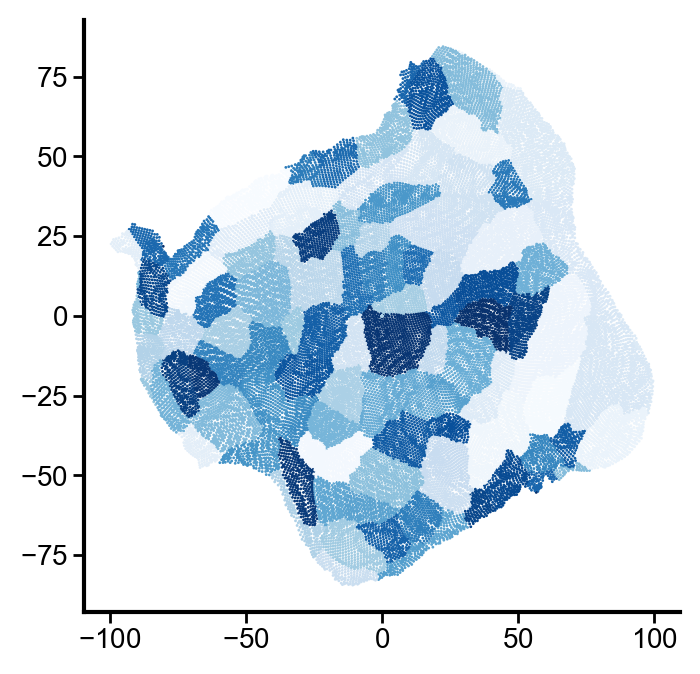

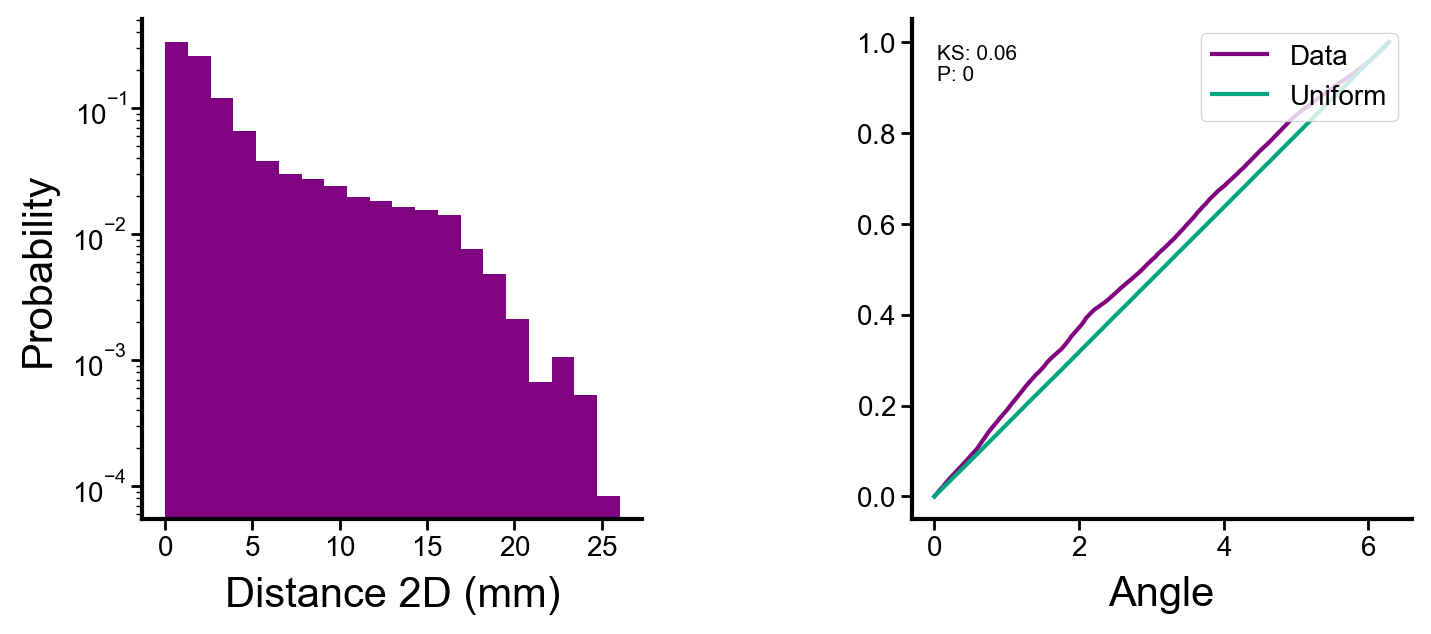

In [25]:
# 文件路径
file_path_cells = r'../../raw_data/marmoset_V4/injection/all_cells.func.gii'
file_path_inject = r'../../raw_data/marmoset_V4/injection/all_inject.func.gii'

# 使用nibabel加载文件
all_cells = nib.load(file_path_cells)
all_inject = nib.load(file_path_inject)
inject_num = len(all_inject.darrays)

# 打印注射次数
print("Cells Data Num:", len(all_cells.darrays))
print("Inject Data Num:", len(all_inject.darrays))

# 打印数据最大值
print(np.max(all_cells.darrays[0].data))
print(np.max(all_inject.darrays[0].data))

# 读取flatmap文件
flatmap_gii = nib.load('../../raw_data/marmoset_V4/Template/lh.full.flat.patch.surf.gii')
print(flatmap_gii)
print(flatmap_gii.meta.metadata)
print(flatmap_gii.darrays[0].data.shape)
print(flatmap_gii.darrays[1].data.shape)

flatmap = flatmap_gii.darrays[0].data

# 对调x和y,并将y取负数,为了和paxinos的坐标系一致
flatmap = np.array([flatmap[:, 1], -flatmap[:, 0], flatmap[:, 2]]).T

# 读取surface文件
surface_gii = nib.load('../../raw_data/marmoset_V4/Template/lh.graymid.surf.gii')
surface = surface_gii.darrays[0].data

# 读取v4对应的label文件
v4_label_gii = nib.load('../../raw_data/marmoset_V4/MBMv4-only/surfFS.lh.MBMv4_cortex_parcellation.label.gii')
print(v4_label_gii.darrays[0].data.shape)
print(set(v4_label_gii.darrays[0].data))
v4_label = v4_label_gii.darrays[0].data

paxinos_label_gii = nib.load('../../raw_data/marmoset_V4/Template/lh.MBM_cortex_vPaxinos.label.gii')
paxinos_label = paxinos_label_gii.darrays[0].data

paxinos_atlas_labels = pd.read_excel('../../raw_data/marmoset_V4/paxinos/atlas_labels.xlsx')
paxinos_area_name = {}
for i in range(len(paxinos_atlas_labels)):
    paxinos_area_name[i] = paxinos_atlas_labels['Area'][i]

# 标出label==97的位置,这个位置应该是原先没有脑区的地方,不用管
fig, ax = plt.subplots()
plt.scatter(flatmap[:, 0], flatmap[:, 1], c=v4_label, s=1, cmap=plt.cm.get_cmap('Blues'))
xrange = np.max(flatmap[:, 0])-np.min(flatmap[:, 0])
yrange = np.max(flatmap[:, 1])-np.min(flatmap[:, 1])
print('xrange:', xrange)
print('yrange:', yrange)

# plt.scatter(flatmap[v4_label == 97, 0], flatmap[v4_label == 97, 1], c='r', s=1)

full_areas = range(1, len(set(v4_label)))

# 计算距离
distance = []
angle = []

inject_areas = []
injection_site = {}
max_site = {}
for i in range(len(all_cells.darrays)):
    tracer_result = {}
    print('-------------------')
    print('i:', i)
    inject = all_inject.darrays[i].data
    cell = all_cells.darrays[i].data
    print('cell shape:', cell.shape)


    if i not in [61, 71, 72, 94, 98, 136]:
        # 得到加权重心对应的脑区
        centroid = get_weighted_centroid(inject, flatmap)
        # 得到flatmap所有点离重心最近的点
        centroid_idx = np.argmin(np.sum((flatmap - centroid) ** 2, axis=1))

        # 得到max injection对应的脑区
        max_injection_idx = np.argmax(inject)
        max_site[i] = flatmap[max_injection_idx]

        # 打印脑区
        print('Paxinos centroid label:', paxinos_area_name[paxinos_label[centroid_idx]])
        print('V4 centroid label:', v4_label[centroid_idx])
        print('Paxinos max label:', paxinos_area_name[paxinos_label[max_injection_idx]])
        print('V4 max label:', v4_label[max_injection_idx])

        if i in [91, 97]:
            # 使用injection max作为注射位置
            injection_site[i] = flatmap[max_injection_idx]
            inject_area = v4_label[max_injection_idx]
        else:
            # 使用加权重心作为注射位置
            injection_site[i] = flatmap[centroid_idx]
            inject_area = v4_label[centroid_idx]
        inject_areas.append(inject_area)

        # 计算注射位置到所有点的距离
        int_cell = cell.astype(int)
        distance_to_repeat = np.sqrt(((flatmap[:, 0] - injection_site[i][0])/xrange*xscale)**2+((flatmap[:, 1] - injection_site[i][1])/yrange*yscale)**2)
        print(distance_to_repeat.shape)
        local_distance = cf.repeat_data(distance_to_repeat, int_cell)
        distance.append(local_distance)

        # 计算角度
        scaled_flatmap = np.array([flatmap[:, 0]/xrange*xscale, flatmap[:, 1]/yrange*yscale]).T
        scaled_injection_site = np.array([injection_site[i][0]/xrange*xscale, injection_site[i][1]/yrange*yscale])
        angle_to_repeat = cf.get_angle(scaled_flatmap, scaled_injection_site)
        local_angle = cf.repeat_data(angle_to_repeat, int_cell)
        angle.append(local_angle)

        # 得到cells最大值处在的脑区
        max_area = np.argmax(cell)
        print('Max voxel in Paxinos:', paxinos_area_name[paxinos_label[max_area]])
        print('Max voxel in V4:', v4_label[max_area])
        print('Max voxel value:', cell[max_area])

distance = np.concatenate(distance)
angle = np.concatenate(angle)

fig, axes = cf.get_fig_ax(ncols=2)

ax = axes[0]
cf.plt_hist(ax, distance, color=cf.PURPLE)
cf.set_ax(ax, xlabel='Distance 2D (mm)', ylog=True)

ax = axes[1]
uniform_angle_data = np.random.uniform(0., 2 * np.pi, len(angle))
cf.plt_compare_cdf_ks(ax, angle, uniform_angle_data, label1='data', label2='uniform', color1=cf.PURPLE, color2=cf.GREEN)
cf.set_ax(ax, xlabel='Angle')